# Bayesian mediation analysis with Bambi

Mediation analysis separates a relationship between a predictor $x$ and an outcome $y$
into a direct path and a path through an observed mediator $m$. This example translates
Benjamin T. Vincent's [PyMC mediation example](https://github.com/pymc-devs/pymc-examples/blob/14a7fde2a1a90be36406c8cd4d82b3a29e0b104e/examples/case_studies/mediation_analysis.ipynb)
into Bambi, preserving its simulated data, priors and total-effect comparison.

We fit three Gaussian regression models in Bambi, derive posterior draws for the
indirect and total effects, and compare them with the original mathematical models
expressed in current PyMC. The comparison checks the translation; it does not turn
an arbitrary observational regression into an identified causal model.

## What can be interpreted causally?

Here $x$ is the exposure, $m$ the mediator and $y$ the outcome. Our simulation explicitly
generates $x \rightarrow m \rightarrow y$ and $x \rightarrow y$, with independent errors.
For causal interpretation in an application, we also need consistency, positivity,
appropriate temporal ordering, no unmeasured exposure–outcome or exposure–mediator
confounding, no unmeasured mediator–outcome confounding, and no exposure-induced
mediator–outcome confounder. The formulas below additionally assume linear additive
relationships without an exposure–mediator interaction. These assumptions require
substantive justification; fitting the model cannot verify them.

Mediation is different from moderation: we model an intervening pathway, not an
interaction that changes the exposure's effect.


In [1]:
%matplotlib inline
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xarray as xr
import pymc as pm
import bambi as bmb
import arviz_stats as azs
from IPython.display import display

SETTINGS = dict(draws=1000, tune=4000, chains=4, cores=4, progressbar=False)


## Simulate the observed data

The data-generating equations are
$m_i \sim \mathrm{Normal}(i_M+a x_i,\sigma_M)$ and
$y_i \sim \mathrm{Normal}(i_Y+c'x_i+b m_i,\sigma_Y)$.
The direct effect is $c'$, the indirect effect is $ab$, and the total effect is
$c'+ab$. The known simulation values are $0.3$, $0.5\times0.6=0.3$, and $0.6$.
Finite-sample posterior estimates need not equal those values.

Generate the arrays once and use exactly the same observations for every fit.


,effect,simulation_value
0,direct,0.3
1,indirect,0.3
2,total,0.6


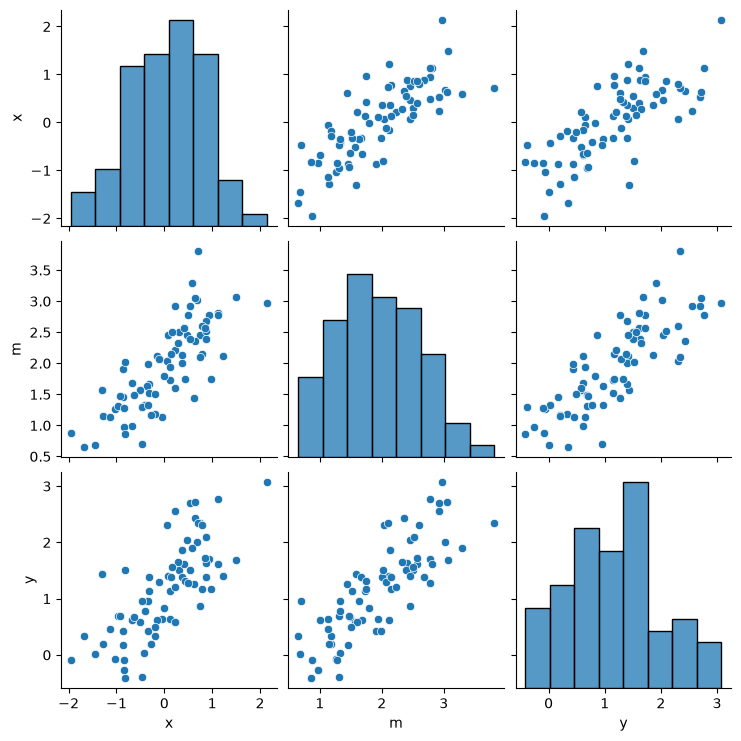

In [2]:
rng = np.random.default_rng(42)
N = 75
x = rng.normal(size=N)
m = 2.0 + rng.normal(loc=0.5 * x, scale=0.5, size=N)
y = 0.3 * x + rng.normal(loc=0.6 * m, scale=0.5, size=N)
data = pd.DataFrame({"x": x, "m": m, "y": y})
array_identity = {
    name: {"shape": list(value.shape), "dtype": str(value.dtype),
           "sha256": hashlib.sha256(value.tobytes()).hexdigest()}
    for name, value in (("x", x), ("m", m), ("y", y))
}
display(pd.DataFrame({"effect": ["direct", "indirect", "total"],
                      "simulation_value": [0.3, 0.5 * 0.6, 0.3 + 0.5 * 0.6]}))
sns.pairplot(data)
plt.show()


## Build the Bambi models with matching priors

The mediator model is `m ~ x`; the outcome model is `y ~ m + x`. Both use
$\mathrm{Normal}(0,10)$ priors for their intercepts and slopes and a scalar
$\mathrm{HalfCauchy}(1)$ residual-scale prior. Explicit priors, `auto_scale=False`
and `center_predictors=False` preserve the original priors' meaning. Default prior
scaling or predictor centering would change this comparison.

The third model, `y ~ x`, estimates the total relationship without conditioning on
the mediator. As in the reference, its intercept and slope instead use
$\mathrm{Normal}(0,1)$ priors. It is not the same posterior model as the mediation
decomposition, so their total-effect posteriors need not be identical.


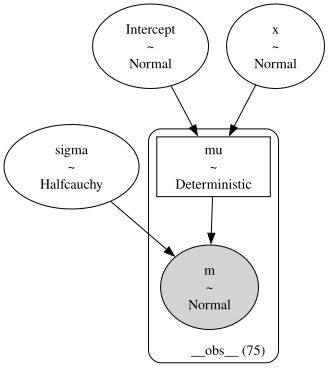

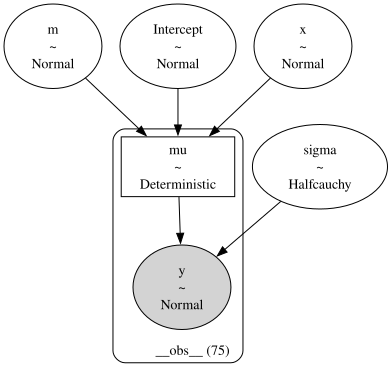

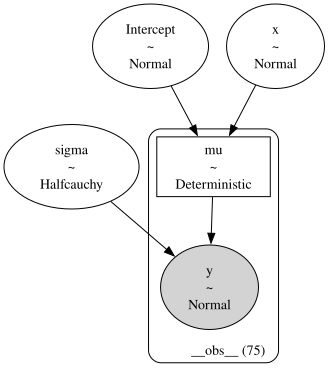

In [3]:
def gaussian_model(formula, terms, prior_scale):
    priors = {name: bmb.Prior("Normal", mu=0, sigma=prior_scale) for name in terms}
    priors["sigma"] = bmb.Prior("HalfCauchy", beta=1)
    model = bmb.Model(formula, data, priors=priors,
                      center_predictors=False, auto_scale=False)
    model.build()
    return model

mediator_model = gaussian_model("m ~ x", ["Intercept", "x"], 10)
outcome_model = gaussian_model("y ~ m + x", ["Intercept", "m", "x"], 10)
total_model = gaussian_model("y ~ x", ["Intercept", "x"], 1)
for model in (mediator_model, outcome_model, total_model):
    display(pm.model_to_graphviz(model.backend.model))


## Why separate fits reproduce this joint model

The mediator is observed, and the two likelihoods have disjoint parameters with
independent priors. Conditional on the observed data, the joint posterior therefore
factorizes into the mediator-model and outcome-model posteriors. We can draw from
those two blocks independently and combine the draws. Preserve the joint draws of
$b$ and $c'$ within the outcome model; shuffling them independently would discard
their posterior dependence.

This reasoning is specific to this model. A latent mediator, shared parameters,
correlated residuals or dependent priors can break the factorization. A custom
joint family is not necessary for this observed-mediator example.

The following PyMC reference definitions preserve the original mathematical model.
`pm.Data` replaces the historical `pm.ConstantData`; the observed arrays never change.
Before sampling we compare complete log densities at several fixed parameter points.


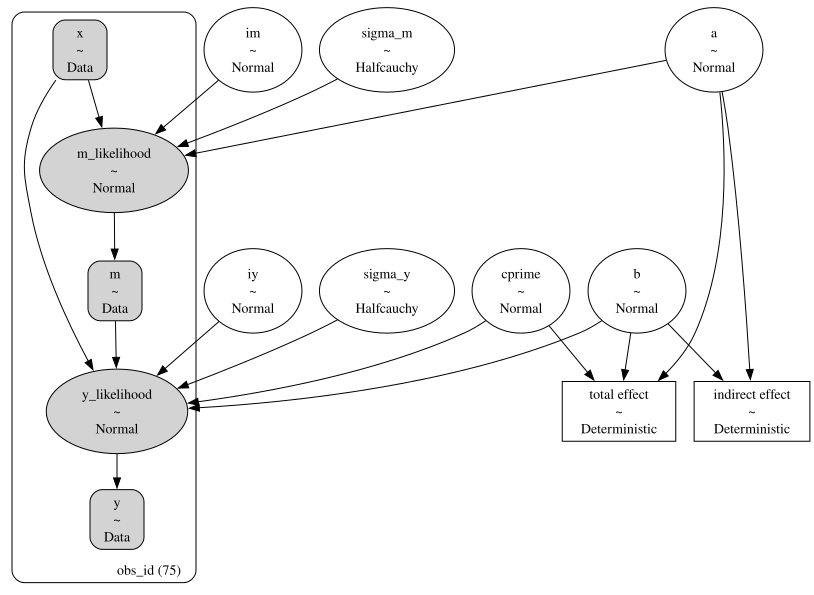

In [4]:
coords = {"obs_id": np.arange(N)}
with pm.Model(coords=coords) as reference_joint:
    xd = pm.Data("x", x, dims="obs_id")
    md = pm.Data("m", m, dims="obs_id")
    yd = pm.Data("y", y, dims="obs_id")
    im = pm.Normal("im", np.float64(0), np.float64(10))
    iy = pm.Normal("iy", np.float64(0), np.float64(10))
    a = pm.Normal("a", np.float64(0), np.float64(10))
    b = pm.Normal("b", np.float64(0), np.float64(10))
    cp = pm.Normal("cprime", np.float64(0), np.float64(10))
    sm = pm.HalfCauchy("sigma_m", np.float64(1))
    sy = pm.HalfCauchy("sigma_y", np.float64(1))
    pm.Normal("m_likelihood", im + a * xd, sm, observed=md, dims="obs_id")
    pm.Normal("y_likelihood", iy + b * md + cp * xd, sy, observed=yd, dims="obs_id")
    pm.Deterministic("indirect effect", a * b)
    pm.Deterministic("total effect", a * b + cp)

with pm.Model(coords=coords) as reference_total:
    xd = pm.Data("_x", x, dims="obs_id")
    iy = pm.Normal("iy", np.float64(0), np.float64(1))
    c = pm.Normal("c", np.float64(0), np.float64(1))
    sy = pm.HalfCauchy("sigma_y", np.float64(1))
    pm.Normal("yy", iy + c * xd, sy, observed=y, dims="obs_id")

display(pm.model_to_graphviz(reference_joint))


In [5]:
def compare_density(actual, expected, log_normalizers):
    actual = np.asarray(actual)
    expected = np.asarray(expected, dtype=np.float64)
    assert actual.dtype == np.dtype('float64') and actual.shape == expected.shape
    assert actual.ndim == 1 and len(actual) >= 3
    assert np.isfinite(actual).all() and np.isfinite(expected).all()
    # At most 32 float64 elementary operations plus subtraction. This bound is
    # distinct from the few low-precision constant logs in normalized PyMC logp.
    eps = np.finfo(np.float64).eps
    gamma = 32 * eps / (1 - 32 * eps)
    arithmetic = gamma * max(1.0, float(np.max(np.abs(actual))), float(np.max(np.abs(expected))))
    # PyMC integer-constant logs may be float32: a four-ULP engineering allowance
    # applies only to constant normalization, never the strict float64 shape.
    normalizer = sum(4 * abs(float(np.spacing(np.float32(term))))
                     for term in log_normalizers)
    np.testing.assert_allclose(actual - actual[0], expected - expected[0],
                               rtol=0, atol=2 * arithmetic)
    np.testing.assert_allclose(actual, expected, rtol=0, atol=normalizer + arithmetic)
    return {'actualDtype': str(actual.dtype), 'float64ArithmeticBound': arithmetic,
            'constantLogEngineeringAllowance': normalizer,
            'normalizerAllowanceIsNotAnAccuracyTheorem': True,
            'maximumAbsoluteError': float(np.max(np.abs(actual - expected))),
            'maximumCenteredShapeError': float(np.max(np.abs(
                (actual - actual[0]) - (expected - expected[0]))))}


def assert_scalar_prior(model, name, distribution, parameters):
    variable = model.named_vars[name]
    assert type(variable.owner.op).__name__.lower().startswith(distribution)
    assert tuple(variable.eval().shape) == ()
    if distribution == 'normal':
        assert set(parameters) == {'mu', 'sigma'} and parameters['sigma'] > 0
        values = np.array([-2.0, 0.0, 3.0], dtype=np.float64)
        mu, sigma = parameters['mu'], parameters['sigma']
        expected = -0.5 * np.log(2 * np.pi) - np.log(sigma) - 0.5 * ((values - mu) / sigma)**2
        normalizers = [np.log(np.sqrt(2 * np.pi)), np.log(sigma)]
    elif distribution == 'halfcauchy':
        assert set(parameters) == {'beta'} and parameters['beta'] > 0
        values = np.array([0.2, 1.0, 3.0], dtype=np.float64)
        beta = parameters['beta']
        expected = np.log(2) - np.log(np.pi) - np.log(beta) - np.log1p((values / beta)**2)
        normalizers = [np.log(2), np.log(np.pi), np.log(beta)]
        assert np.isneginf(np.asarray(pm.logp(variable, -1.0).eval())).all()
    else:
        raise AssertionError('Unsupported prior check: ' + distribution)
    return compare_density(np.asarray(pm.logp(variable, values).eval()), expected, normalizers)

for model, terms, scale in [
    (reference_joint, ["im", "iy", "a", "b", "cprime"], 10),
    (reference_total, ["iy", "c"], 1),
    (mediator_model.backend.model, ["Intercept", "x"], 10),
    (outcome_model.backend.model, ["Intercept", "m", "x"], 10),
    (total_model.backend.model, ["Intercept", "x"], 1),
]:
    for name in terms:
        assert_scalar_prior(model, name, "normal", {"mu": 0, "sigma": scale})
    scales = (["sigma_m", "sigma_y"] if model is reference_joint else
              ["sigma_y"] if model is reference_total else ["sigma"])
    for name in scales:
        assert_scalar_prior(model, name, "halfcauchy", {"beta": 1})
    assert {variable.name for variable in model.free_RVs} == set(terms + scales)
np.testing.assert_array_equal(reference_joint["x"].get_value(), x)
np.testing.assert_array_equal(reference_joint["m"].get_value(), m)
np.testing.assert_array_equal(reference_joint["y"].get_value(), y)

def parameter_point(model, values):
    point = model.initial_point()
    for name, value in values.items():
        target = name + "_log__" if name.startswith("sigma") else name
        assert target in point
        point[target] = np.asarray(np.log(value) if name.startswith("sigma") else value)
    assert set(point) == {name + "_log__" if name.startswith("sigma") else name
                          for name in values}
    return point

logps = [model.compile_logp() for model in
         (reference_joint, reference_total, mediator_model.backend.model,
          outcome_model.backend.model, total_model.backend.model)]
for im, iy, a, b, cp, sm, sy in [
    (2, 0, .5, .6, .3, .5, .5),
    (1.2, -.8, -.2, 1.1, .9, .7, 1.2),
    (-1, 2, 1.5, -.7, -.2, 1.1, .3),
]:
    joint = logps[0](parameter_point(reference_joint, dict(
        im=im, iy=iy, a=a, b=b, cprime=cp, sigma_m=sm, sigma_y=sy)))
    mediator = logps[2](parameter_point(mediator_model.backend.model, dict(
        Intercept=im, x=a, sigma=sm)))
    outcome = logps[3](parameter_point(outcome_model.backend.model, dict(
        Intercept=iy, m=b, x=cp, sigma=sy)))
    total = logps[1](parameter_point(reference_total, dict(iy=iy, c=cp, sigma_y=sy)))
    native_total = logps[4](parameter_point(total_model.backend.model, dict(
        Intercept=iy, x=cp, sigma=sy)))
    np.testing.assert_allclose(joint, mediator + outcome, rtol=1e-11, atol=1e-8)
    np.testing.assert_allclose(total, native_total, rtol=1e-11, atol=1e-8)


## Sample all five models

Use four chains, 4,000 tuning iterations and 1,000 retained draws per chain, with
`target_accept=0.9`. Separate seeds give independent Monte Carlo samples for the
independent blocks; we compare distributions, not exact draws or historical means.
The PyMC references run first to retain the same comparison protocol as validation.


In [6]:
with reference_joint:
    reference_joint_fit = pm.sample(**SETTINGS, nuts={"target_accept": 0.9}, random_seed=417)
with reference_total:
    reference_total_fit = pm.sample(**SETTINGS, nuts={"target_accept": 0.9}, random_seed=419)
mediator_fit = mediator_model.fit(inference_method="pymc", **SETTINGS,
                                  random_seed=421, nuts={"target_accept": 0.9})
outcome_fit = outcome_model.fit(inference_method="pymc", **SETTINGS,
                                random_seed=431, nuts={"target_accept": 0.9})
total_fit = total_model.fit(inference_method="pymc", **SETTINGS,
                            random_seed=433, nuts={"target_accept": 0.9})
fits = {"reference joint": reference_joint_fit, "reference total": reference_total_fit,
        "Bambi mediator": mediator_fit, "Bambi outcome": outcome_fit,
        "Bambi total": total_fit}


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [im, iy, a, b, cprime, sigma_m, sigma_y]


Sampling 4 chains for 4_000 tune and 1_000 draw iterations (16_000 + 4_000 draws total) took 9 seconds.


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


... (10 outputs left out)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [sigma, Intercept, x]


Sampling 4 chains for 4_000 tune and 1_000 draw iterations (16_000 + 4_000 draws total) took 3 seconds.


## Check convergence before interpreting effects

Check finite samples, four chains and 1,000 draws, no divergences, R-hat below 1.01,
and both bulk and tail effective sample sizes of at least 400. Inspect the trace
plots as well; a passing numerical threshold alone is not a guarantee of accuracy.
The current result groups may be DataTree nodes, so access their underlying datasets.


In [7]:
def dataset(group):
    return group.ds if isinstance(group, xr.DataTree) else group

posteriors = {}
diagnostics = []
for name, fit in fits.items():
    posterior = dataset(fit["posterior"])
    sample_stats = dataset(fit["sample_stats"])
    assert posterior.sizes["chain"] == 4 and posterior.sizes["draw"] == 1000
    assert np.isfinite(posterior.to_array()).all()
    divergent = int(sample_stats["diverging"].sum())
    rhat = float(azs.rhat(posterior).to_array().max())
    bulk = float(azs.ess(posterior, method="bulk").to_array().min())
    tail = float(azs.ess(posterior, method="tail").to_array().min())
    assert divergent == 0 and rhat < 1.01 and bulk >= 400 and tail >= 400
    diagnostics.append(dict(model=name, divergences=divergent, max_rhat=rhat,
                            min_bulk_ess=bulk, min_tail_ess=tail))
    posteriors[name] = posterior
display(pd.DataFrame(diagnostics))


,model,divergences,max_rhat,min_bulk_ess,min_tail_ess
0,reference joint,0,1.003389,1395.989332,1694.353541
1,reference total,0,1.001464,3237.675971,2747.996683
2,Bambi mediator,0,1.000245,3549.759432,2713.105696
3,Bambi outcome,0,1.003272,1062.504565,1423.283167
4,Bambi total,0,1.001258,3741.271626,2817.518020


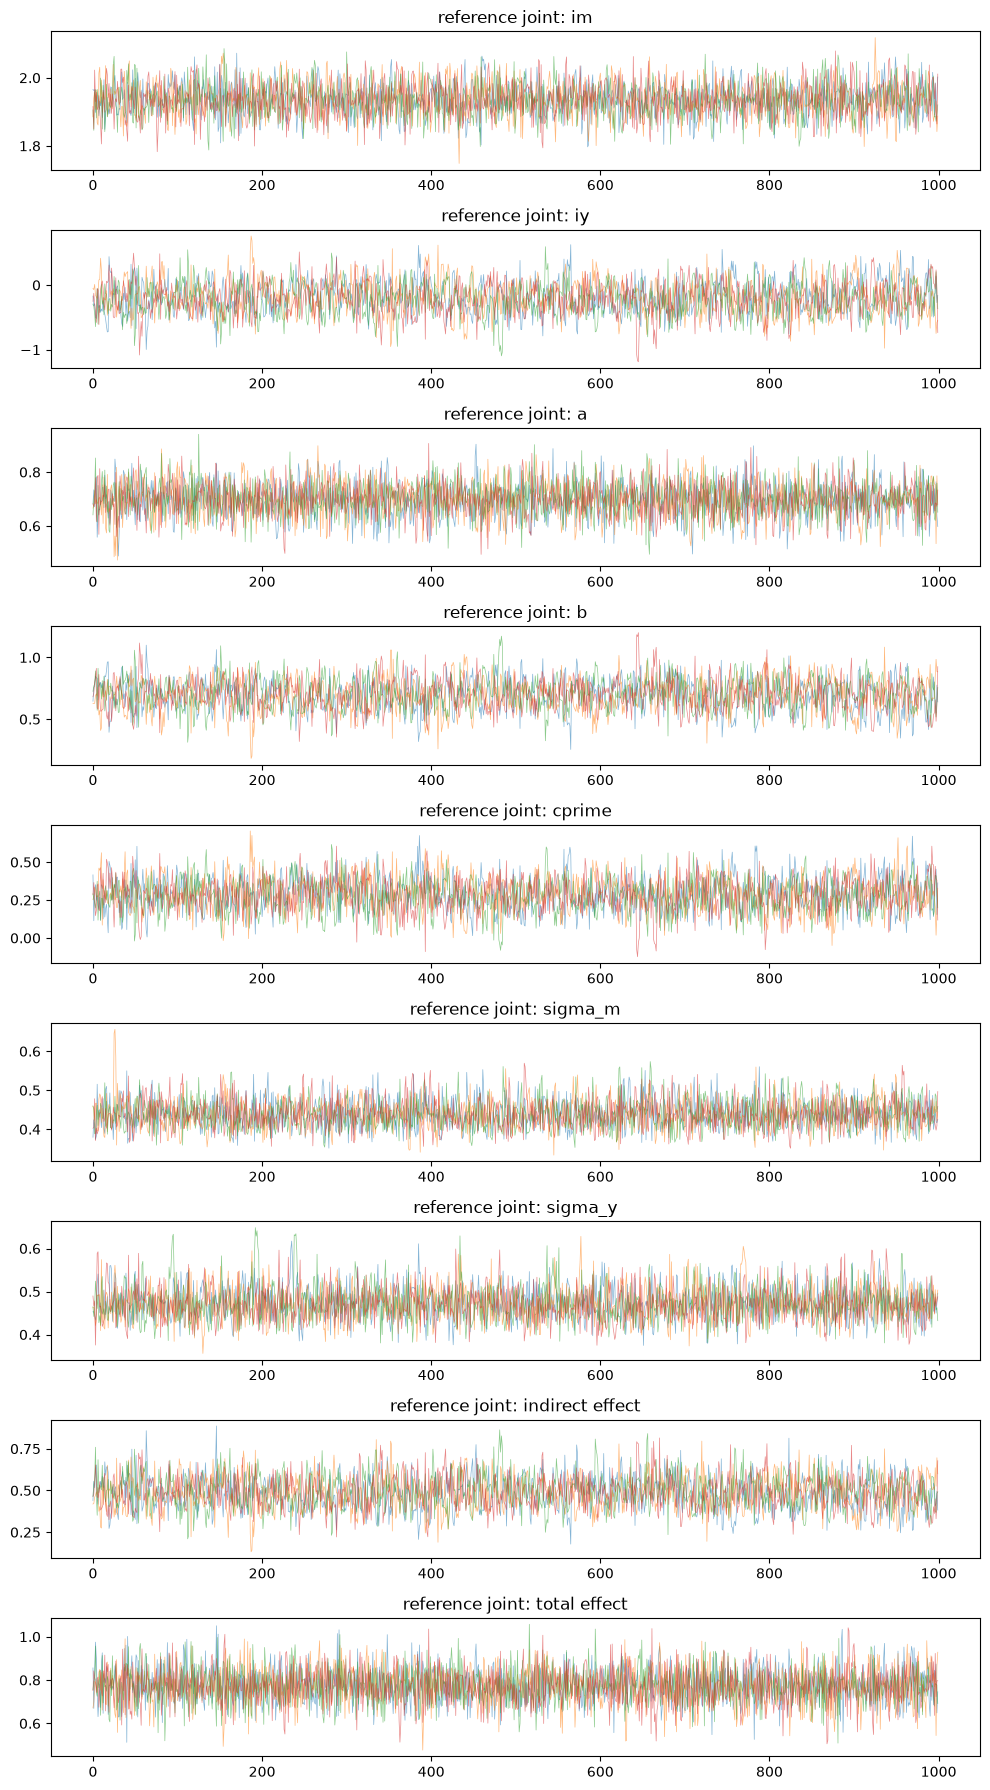

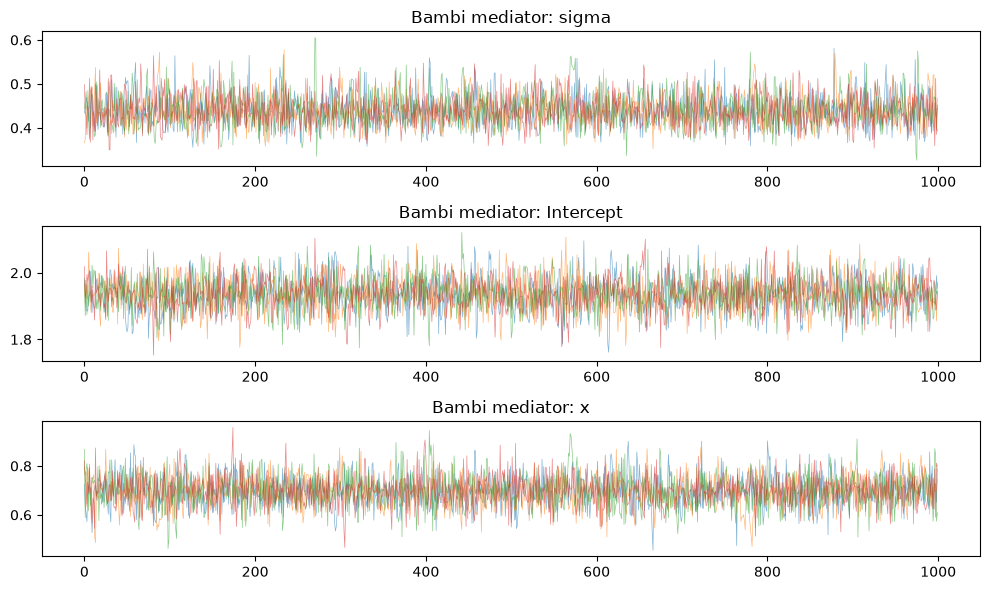

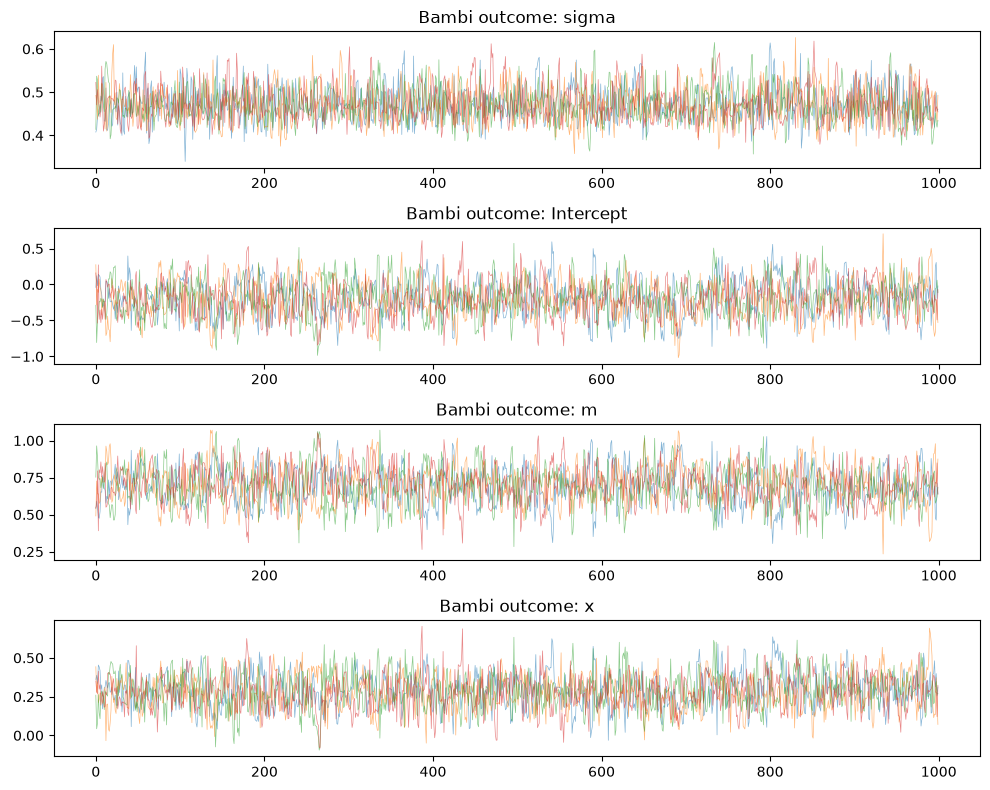

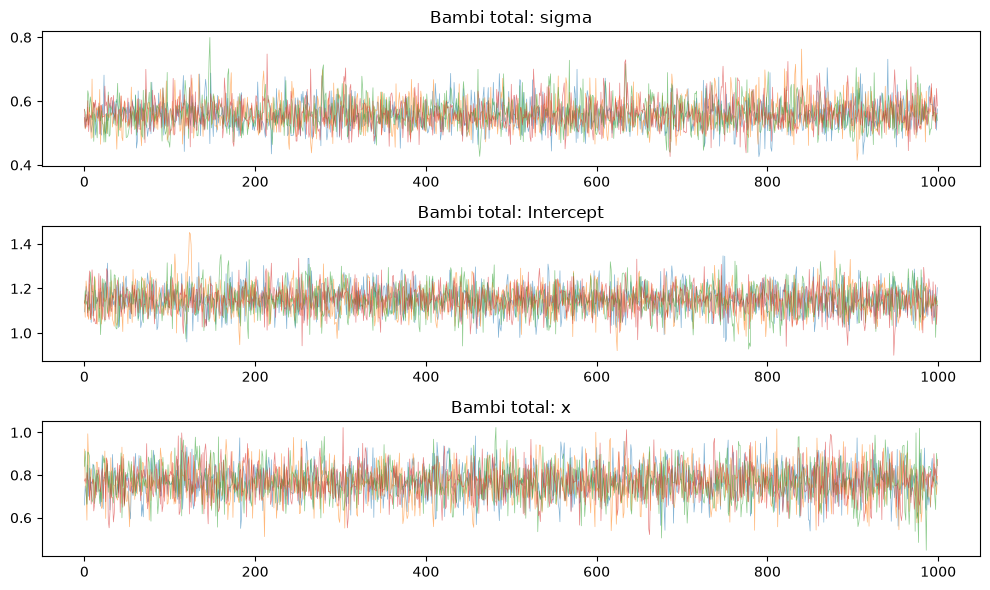

In [8]:
for name in ("reference joint", "Bambi mediator", "Bambi outcome", "Bambi total"):
    posterior = posteriors[name]
    fig, axes = plt.subplots(len(posterior.data_vars), 1,
                             figsize=(10, 2 * len(posterior.data_vars)), squeeze=False)
    for ax, (parameter, values) in zip(axes[:, 0], posterior.data_vars.items()):
        for chain in range(4):
            ax.plot(values.isel(chain=chain), alpha=0.55, lw=0.5)
        ax.set_title(f"{name}: {parameter}")
    fig.tight_layout()
    plt.show()


## Derive direct, indirect and total effects

Multiply aligned independent mediator and outcome draws to obtain $ab$; add the
outcome model's $c'$ from that same outcome draw to obtain $c'+ab$. Within-outcome
dependence between $b$ and $c'$ is retained. Each table value below comes from this
execution, rather than the historical example's printed estimates.


,effect,mean,hdi95_lower,hdi95_upper,mcse_mean
0,direct,0.283223,0.069020,0.502543,0.003305
1,indirect,0.487222,0.312091,0.697217,0.002733
2,total,0.770446,0.602492,0.935021,0.001610


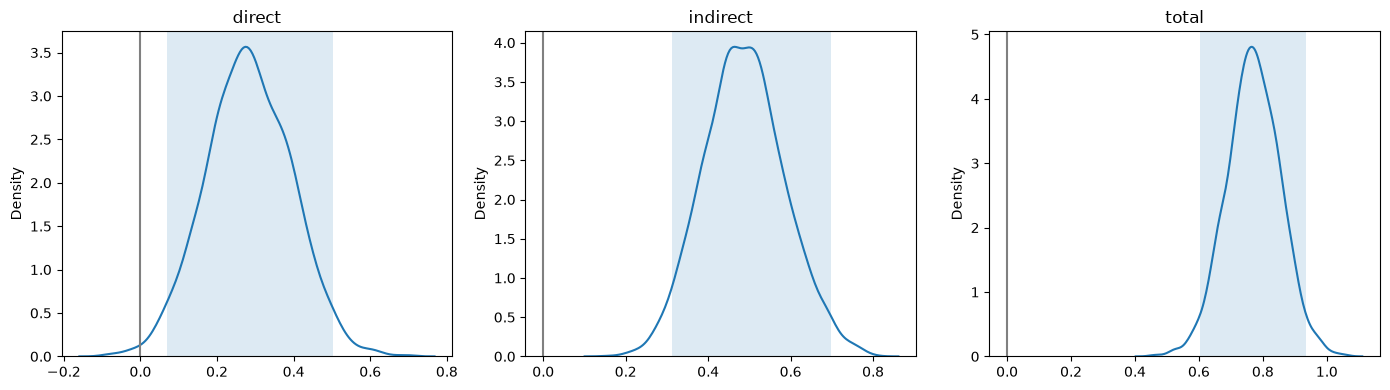

In [9]:
mediator = posteriors["Bambi mediator"]
outcome = posteriors["Bambi outcome"]
effects = xr.Dataset({"direct": outcome["x"],
                      "indirect": mediator["x"] * outcome["m"],
                      "total": outcome["x"] + mediator["x"] * outcome["m"]})
effect_rows = []
for name, values in effects.data_vars.items():
    interval = np.asarray(azs.hdi(values, prob=0.95)).ravel()
    effect_rows.append({"effect": name, "mean": float(values.mean()),
                        "hdi95_lower": float(interval.min()),
                        "hdi95_upper": float(interval.max()),
                        "mcse_mean": float(azs.mcse(values, method="mean"))})
display(pd.DataFrame(effect_rows))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, values) in zip(axes, effects.data_vars.items()):
    interval = np.asarray(azs.hdi(values, prob=0.95)).ravel()
    sns.kdeplot(values.values.ravel(), ax=ax)
    ax.axvline(0, color="gray")
    ax.axvspan(float(interval.min()), float(interval.max()), alpha=0.15)
    ax.set_title(name)
fig.tight_layout()
thumbnail = Path("thumbnails/mediation_analysis.png")
assert thumbnail.parent.is_dir()
fig.savefig(thumbnail, dpi=100)
plt.show()


For a one-unit exposure contrast in this linear model, the direct effect describes
the path through $c'$, the indirect effect describes the path through $ab$, and their
sum describes the total effect under the stated assumptions. A 95% highest-density
interval summarizes uncertainty; it does not by itself test a point-null hypothesis.
With continuous priors the posterior assigns no point mass to exactly zero, even
when the data provide little practical information about an effect.


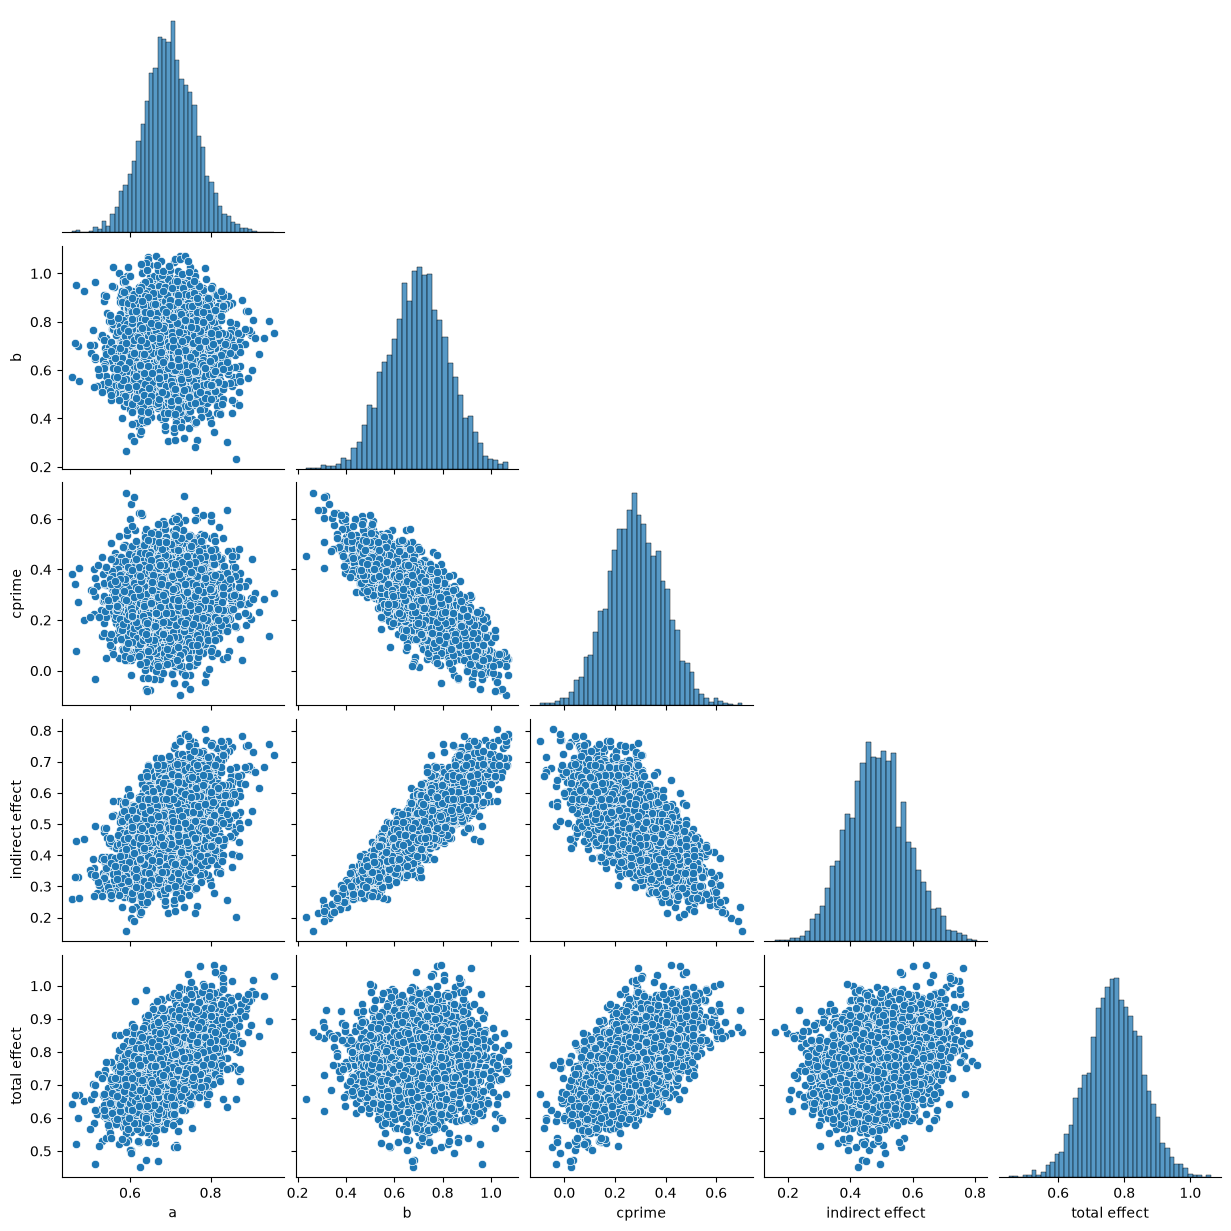

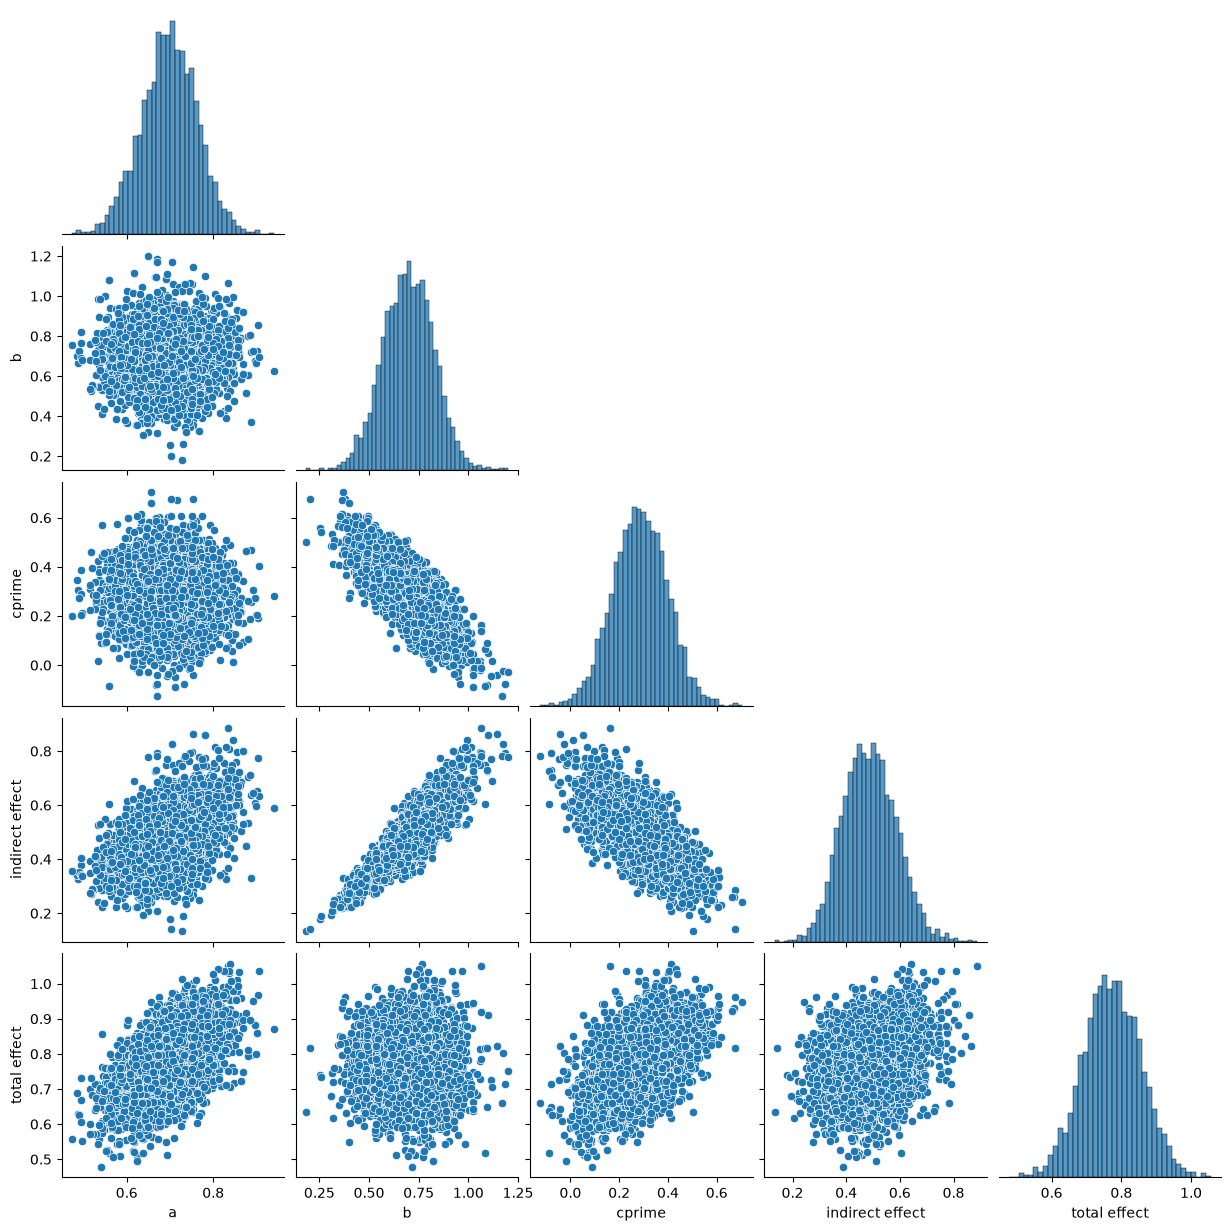

In [10]:
native_pair_values = {"a": mediator["x"], "b": outcome["m"],
                      "cprime": outcome["x"], "indirect effect": effects["indirect"],
                      "total effect": effects["total"]}
sns.pairplot(pd.DataFrame({name: values.values.ravel()
                          for name, values in native_pair_values.items()}), corner=True)
plt.show()
reference = posteriors["reference joint"]
sns.pairplot(pd.DataFrame({name: reference[name].values.ravel()
                          for name in ("a", "b", "cprime", "indirect effect", "total effect")}),
             corner=True)
plt.show()


## Check the Bambi translation against PyMC

The six comparisons below match each Bambi quantity to its corresponding PyMC
quantity, including the separately fitted total-only model. The reference and Bambi
samples are independent, so their mean differences should be assessed relative to
their combined Monte Carlo standard errors. The four-combined-MCSE check is a
predeclared numerical translation diagnostic, not a causal-identification test.


In [11]:
native_parameters = {"a": mediator["x"], "b": outcome["m"], "cprime": outcome["x"],
                     "indirect effect": effects["indirect"], "total effect": effects["total"]}
pairs = [(name, reference[name], values) for name, values in native_parameters.items()]
pairs.append(("total-only slope", posteriors["reference total"]["c"],
              posteriors["Bambi total"]["x"]))
comparison = []
for name, expected, actual in pairs:
    reference_mcse = float(azs.mcse(expected, method="mean"))
    native_mcse = float(azs.mcse(actual, method="mean"))
    tolerance = 4 * np.sqrt(reference_mcse**2 + native_mcse**2)
    difference = abs(float(expected.mean()) - float(actual.mean()))
    assert difference <= tolerance
    comparison.append(dict(quantity=name, reference_mean=float(expected.mean()),
                            bambi_mean=float(actual.mean()), absolute_difference=difference,
                            four_combined_mcse=tolerance))
display(pd.DataFrame(comparison))


,quantity,reference_mean,bambi_mean,absolute_difference,four_combined_mcse
0,a,0.698613,0.697468,0.001144,0.005985
1,b,0.697854,0.698638,0.000784,0.020653
2,cprime,0.285675,0.283223,0.002451,0.017261
3,indirect effect,0.487529,0.487222,0.000306,0.014789
4,total effect,0.773203,0.770446,0.002758,0.007985
5,total-only slope,0.769111,0.766656,0.002455,0.007541


## Compare the two total-effect models

Compare the mediation **total** $c'+ab$ with the slope $c$ from `y ~ x`, not the
direct effect $c'$. Their priors differ: the decomposition uses Normal(0,10)
coefficient priors, whereas the total-only regression uses Normal(0,1). Their
residual models and induced priors on the total also differ. Similar distributions
in this simulated example are a useful comparison, not a general equality theorem
or a reason to equate total and direct effects.


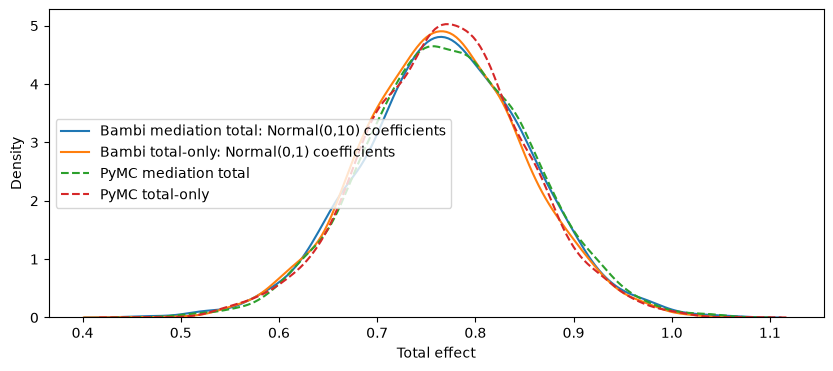

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.kdeplot(effects["total"].values.ravel(), ax=ax,
             label="Bambi mediation total: Normal(0,10) coefficients")
sns.kdeplot(posteriors["Bambi total"]["x"].values.ravel(), ax=ax,
             label="Bambi total-only: Normal(0,1) coefficients")
sns.kdeplot(reference["total effect"].values.ravel(), ax=ax, linestyle="--",
             label="PyMC mediation total")
sns.kdeplot(posteriors["reference total"]["c"].values.ravel(), ax=ax, linestyle="--",
             label="PyMC total-only")
ax.set_xlabel("Total effect")
ax.legend()
plt.show()


## Parameter estimation and hypothesis testing

This example estimates posterior effect distributions. It does not perform a Bayes
factor comparison, put a spike at zero, or establish that mediation is absent or
present from a point-null probability. A model-comparison question needs explicit
competing models and priors. More generally, a well-fitting regression and narrow
posterior do not establish the causal assumptions listed at the beginning.

## Provenance and references

Adapted from Benjamin T. Vincent's *Bayesian mediation analysis*, authored August
2021 and updated February 2022, in the official PyMC examples repository at commit
`14a7fde2a1a90be36406c8cd4d82b3a29e0b104e`. Its source notebook blob is
`fd6abd95c35e7ee346e011cdc8d8fd3afca6751e`. This adaptation uses current PyMC/Bambi
APIs, explicit independent seeds and current execution summaries; its figures are
generated from the simulated data rather than copied from the original page.
Reference title: *Introduction to Mediation,
Moderation, and Conditional Process Analysis*. Consult the linked original example
for its broader bibliography and history.


## Original example license

```text
MIT License

Copyright (c) 2020 PyMC

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.

```


## Environment

Record the actual versions used by this execution.


In [13]:
%load_ext watermark
%watermark -n -u -v -iv -w -p bambi,pymc,pytensor,arviz_stats,xarray,numpy


Last updated: Sat, 14 Nov 2026

Python implementation: CPython
Python version       : 3.13.18
IPython version      : 9.18.1

bambi      : 0.21.1.dev7+gbabde99af
pymc       : 6.4.0
pytensor   : 3.3.8
arviz_stats: 1.3.3
xarray     : 2026.9.0
numpy      : 2.4.6

IPython    : 9.18.1
arviz_stats: 1.3.3
bambi      : 0.21.1.dev7+gbabde99af
matplotlib : 3.11.2
numpy      : 2.4.6
pandas     : 2.3.3
pymc       : 6.4.0
seaborn    : 0.13.2
xarray     : 2026.9.0

Watermark: 2.6.0

